# MapleFreight late delivery risk + Slack for dispatch

AML 3303 Assessment 1 | Student ID c0968267

## 1. Context

MapleFreight handles on the order of 8,000 shipments weekly across Ontario, Quebec and the Prairies. Contracts promise on-time delivery, so a miss turns into credits and sometimes a paid re-run.

On-time rate dropped from 94% to 88% this year. By the time dispatch hears about a problem, the customer has often called already.

## 2. Problem statement

The business finds out late after the window closes. Credits are owed, re-deliveries get rushed, and account managers get pulled in.

I built a classifier for `delivered_late` and wired high scores into Slack (`#dispatch-alerts`) so someone can act before the trip is finished.

## 3. Objectives

1. See what in the export actually drives lateness (carrier, weather, route, pickup timing).
2. Train a model that beats the dumb baseline on the late class.
3. Post real Slack alerts for high-risk IDs.
4. Write a short list of dispatch changes that follow from the numbers.

## 4. Setup

In [2]:
from pathlib import Path
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dotenv import load_dotenv
import requests

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_recall_fscore_support,
    roc_auc_score,
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
plt.style.use("ggplot")

# Find project root even if the Jupyter kernel starts in another folder
ROOT = Path.cwd()
if not (ROOT / "data" / "maplefreight_delivery_delay_dataset.csv").exists():
    for candidate in [Path.cwd(), *Path.cwd().parents]:
        if (candidate / "data" / "maplefreight_delivery_delay_dataset.csv").exists():
            ROOT = candidate
            break

DATA_PATH = ROOT / "data" / "maplefreight_delivery_delay_dataset.csv"
ENV_PATH = ROOT / ".env"
SCREENSHOT_DIR = ROOT / "screenshots"
RANDOM_STATE = 42
TEST_SIZE = 0.2

load_dotenv(ENV_PATH)
print("Project root:", ROOT)
print("Data exists:", DATA_PATH.exists())
print("Env file:", ENV_PATH.exists())
print("Slack webhook loaded:", bool(os.getenv("SLACK_WEBHOOK_URL")))

Project root: d:\AML-3303-OTT01 Software Tools and Emerging\Assignment1
Data exists: True
Env file: True
Slack webhook loaded: True


## 5. Data understanding

6,035 shipments, 23 columns. Target `delivered_late` is positive about 21% of the time. A model that always says on-time hits ~79% accuracy and catches zero late loads.

`actual_transit_hours` is filled in when the shipment completes. I dropped it so the model cannot cheat with post-delivery information.

In [3]:
df_raw = pd.read_csv(DATA_PATH)
print("Shape:", df_raw.shape)
print("Late rate:", round(df_raw["delivered_late"].mean(), 4))
df_raw.head()

Shape: (6035, 23)
Late rate: 0.2058


,shipment_id,origin_city,destination_city,carrier,service_level,goods_type,customer_priority_tier,shipment_month,distance_km,weight_kg,num_stops,is_cross_border,scheduled_transit_hours,pickup_delay_minutes,driver_experience_years,vehicle_age_years,weather_condition,traffic_index,route_congestion_score,prior_late_deliveries_30d,fuel_cost_cad,actual_transit_hours,delivered_late
0,SHP-103848,Mississauga ON,Edmonton AB,NorthStar Carriers,Standard,General Freight,Bronze,1,376.0,257.1,2,0,7.53,55.0,5.1,6.1,Fog,37.2,0.291,1,146.39,7.55,0
1,SHP-102827,Montreal QC,Winnipeg MB,PrairieLine,Standard,General Freight,Silver,12,159.8,734.1,0,0,1.00,69.0,5.3,4.2,Snow,77.4,0.236,0,155.07,1.17,1
2,SHP-105254,Toronto ON,Hamilton ON,QuebecExpress,Standard,Fragile,Silver,9,423.0,680.8,0,0,7.12,-13.0,1.4,2.8,Rain,36.5,0.344,0,163.44,6.47,0
3,SHP-102719,Montreal QC,Hamilton ON,MapleFreight Fleet,Standard,General Freight,Silver,1,494.1,1292.2,0,0,7.61,-20.0,4.0,14.8,Fog,51.2,0.491,2,NaN,8.03,0
4,SHP-105198,Mississauga ON,Sudbury ON,MapleFreight Fleet,Standard,Refrigerated,Bronze,9,843.5,3327.1,1,0,12.90,28.0,2.9,1.6,Clear,82.7,0.423,1,263.22,13.49,0


In [4]:
df_raw.info()
print("\nMissing values:")
print(df_raw.isna().sum()[df_raw.isna().sum() > 0])
print("\nDuplicate rows:", df_raw.duplicated().sum())
print("\nservice_level value counts:")
print(df_raw["service_level"].value_counts())

<class 'pandas.DataFrame'>
RangeIndex: 6035 entries, 0 to 6034
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   shipment_id                6035 non-null   str    
 1   origin_city                6035 non-null   str    
 2   destination_city           6035 non-null   str    
 3   carrier                    6035 non-null   str    
 4   service_level              6035 non-null   str    
 5   goods_type                 6035 non-null   str    
 6   customer_priority_tier     6035 non-null   str    
 7   shipment_month             6035 non-null   int64  
 8   distance_km                6035 non-null   float64
 9   weight_kg                  6035 non-null   float64
 10  num_stops                  6035 non-null   int64  
 11  is_cross_border            6035 non-null   int64  
 12  scheduled_transit_hours    6035 non-null   float64
 13  pickup_delay_minutes       6035 non-null   float64
 14  dri

Missing counts: `driver_experience_years` 210, `weather_condition` 150, `traffic_index` 121, `fuel_cost_cad` 240. There are 32 duplicate rows. `service_level` has `Standard` and `standard` in the same column, so I normalize casing before training.

## 6. Exploratory data analysis

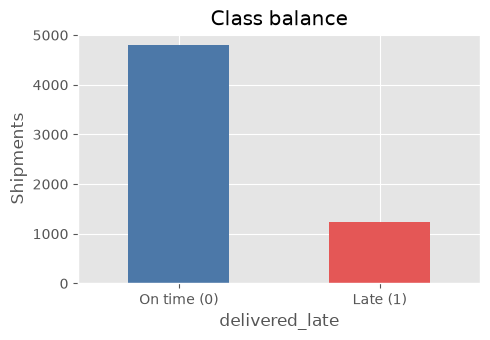

In [5]:
fig, ax = plt.subplots(figsize=(5, 3.5))
df_raw["delivered_late"].value_counts().sort_index().plot(
    kind="bar", ax=ax, color=["#4C78A8", "#E45756"]
)
ax.set_xticklabels(["On time (0)", "Late (1)"], rotation=0)
ax.set_ylabel("Shipments")
ax.set_title("Class balance")
plt.tight_layout()
plt.show()

In [6]:
tmp = df_raw.copy()
tmp["service_level"] = tmp["service_level"].astype(str).str.strip().str.title()

print("Late rate by carrier:")
print(tmp.groupby("carrier")["delivered_late"].mean().sort_values(ascending=False).round(3))
print("\nLate rate by weather:")
print(tmp.groupby("weather_condition")["delivered_late"].mean().sort_values(ascending=False).round(3))
print("\nLate rate by service level:")
print(tmp.groupby("service_level")["delivered_late"].mean().sort_values(ascending=False).round(3))

Late rate by carrier:
carrier
Contract Owner-Op     0.359
PrairieLine           0.265
QuebecExpress         0.224
NorthStar Carriers    0.220
MapleFreight Fleet    0.129
Name: delivered_late, dtype: float64

Late rate by weather:
weather_condition
Storm    0.463
Snow     0.335
Fog      0.213
Rain     0.209
Clear    0.140
Name: delivered_late, dtype: float64

Late rate by service level:
service_level
Economy     0.266
Standard    0.207
Express     0.151
Name: delivered_late, dtype: float64


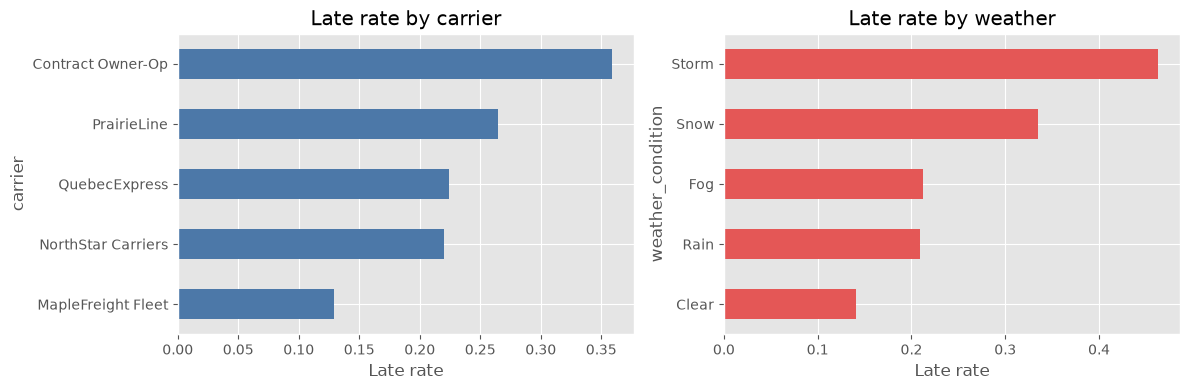

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

carrier_late = tmp.groupby("carrier")["delivered_late"].mean().sort_values()
carrier_late.plot(kind="barh", ax=axes[0], color="#4C78A8")
axes[0].set_xlabel("Late rate")
axes[0].set_title("Late rate by carrier")

weather_late = tmp.groupby("weather_condition")["delivered_late"].mean().sort_values()
weather_late.plot(kind="barh", ax=axes[1], color="#E45756")
axes[1].set_xlabel("Late rate")
axes[1].set_title("Late rate by weather")

plt.tight_layout()
plt.show()

In [8]:
numeric_cols = [
    "distance_km", "weight_kg", "num_stops", "scheduled_transit_hours",
    "pickup_delay_minutes", "driver_experience_years", "vehicle_age_years",
    "traffic_index", "route_congestion_score", "prior_late_deliveries_30d",
    "fuel_cost_cad",
]
late_by_num = tmp.groupby("delivered_late")[numeric_cols].mean().T
late_by_num.columns = ["on_time", "late"]
late_by_num["pct_diff"] = (late_by_num["late"] - late_by_num["on_time"]) / late_by_num["on_time"]
late_by_num.sort_values("pct_diff", ascending=False).round(3)

,on_time,late,pct_diff
pickup_delay_minutes,18.385,28.021,0.524
num_stops,2.343,2.995,0.278
weight_kg,6590.926,8230.021,0.249
scheduled_transit_hours,9.996,12.447,0.245
prior_late_deliveries_30d,1.243,1.546,0.243
distance_km,602.269,747.670,0.241
traffic_index,53.656,60.881,0.135
route_congestion_score,0.440,0.488,0.110
vehicle_age_years,5.380,5.912,0.099
fuel_cost_cad,180.452,181.636,0.007


Contract Owner-Op is late around 36% of the time; MapleFreight Fleet around 13%. Storm days run about 46% late vs clear days around 14%. Economy beats Express on lateness in this file.

Numeric averages: late loads leave pickup later (roughly 52% higher delay minutes), take more stops, run farther and weigh more. Driver experience is a touch lower on late rows. Fuel cost barely separates the classes, so I did not lean on it in the write-up.

## 7. Data preprocessing

Drop duplicates, fix `service_level` spelling, trim category strings, remove `actual_transit_hours`.

In [9]:
def clean_shipments(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    before = len(out)
    out = out.drop_duplicates()
    print(f"Dropped {before - len(out)} duplicate rows")

    out["service_level"] = out["service_level"].astype(str).str.strip().str.title()
    for col in ["weather_condition", "goods_type", "customer_priority_tier", "carrier"]:
        out[col] = out[col].astype(str).str.strip()
        out.loc[out[col].isin(["nan", "None", "<NA>"]), col] = np.nan

    out = out.drop(columns=["actual_transit_hours"])
    return out.reset_index(drop=True)


df = clean_shipments(df_raw)
print("Clean shape:", df.shape)
print(df["service_level"].value_counts())

Dropped 32 duplicate rows
Clean shape: (6003, 22)
service_level
Standard    3278
Express     1460
Economy     1265
Name: count, dtype: int64


After dedupe: 6,003 rows (32 removed). Three service levels remain. Leakage column stays out.

## 8. Feature engineering

In [10]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["km_per_scheduled_hour"] = out["distance_km"] / out["scheduled_transit_hours"].replace(0, np.nan)
    out["pickup_was_late"] = (out["pickup_delay_minutes"] > 0).astype(int)
    out["origin_province"] = out["origin_city"].astype(str).str.extract(r"([A-Z]{2})$")
    out["destination_province"] = out["destination_city"].astype(str).str.extract(r"([A-Z]{2})$")
    return out


df = add_features(df)

print(
    "Late rate if pickup was late:",
    round(df.loc[df["pickup_was_late"] == 1, "delivered_late"].mean(), 3),
)
print(
    "Late rate if pickup was on time/early:",
    round(df.loc[df["pickup_was_late"] == 0, "delivered_late"].mean(), 3),
)
df[["distance_km", "scheduled_transit_hours", "km_per_scheduled_hour", "pickup_was_late"]].describe()


Late rate if pickup was late: 0.232
Late rate if pickup was on time/early: 0.146


,distance_km,scheduled_transit_hours,km_per_scheduled_hour,pickup_was_late
count,6003.000000,6003.000000,6003.000000,6003.000000
mean,632.131901,10.497223,61.080142,0.691488
std,319.362781,4.760570,16.408498,0.461918
min,80.500000,1.000000,14.323843,0.000000
25%,398.450000,7.060000,51.971784,0.000000
50%,571.100000,9.830000,60.153551,1.000000
75%,804.500000,13.170000,68.071397,1.000000
max,2556.700000,37.400000,259.600000,1.000000


If pickup was late (`pickup_was_late`), delivery is late about 23% of the time vs about 15% when pickup was on time or early. I added province codes from the city strings and `km_per_scheduled_hour` as a rough schedule pressure measure instead of passing full city names into the model.

## 9. Data preparation

In [11]:
TARGET = "delivered_late"
ID_COL = "shipment_id"
drop_from_X = [TARGET, ID_COL, "origin_city", "destination_city"]

feature_cols = [c for c in df.columns if c not in drop_from_X]
X = df[feature_cols].copy()
y = df[TARGET]

cat_cols = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()
for c in cat_cols:
    X[c] = X[c].astype(object).where(pd.notna(X[c]), np.nan)
num_cols = [c for c in X.columns if c not in cat_cols]

print("Numeric:", num_cols)
print("Categorical:", cat_cols)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print("Train late rate:", round(y_train.mean(), 4), "| Test late rate:", round(y_test.mean(), 4))

Numeric: ['shipment_month', 'distance_km', 'weight_kg', 'num_stops', 'is_cross_border', 'scheduled_transit_hours', 'pickup_delay_minutes', 'driver_experience_years', 'vehicle_age_years', 'traffic_index', 'route_congestion_score', 'prior_late_deliveries_30d', 'fuel_cost_cad', 'km_per_scheduled_hour', 'pickup_was_late']
Categorical: ['carrier', 'service_level', 'goods_type', 'customer_priority_tier', 'weather_condition', 'origin_province', 'destination_province']
Train: 4802 | Test: 1201
Train late rate: 0.2057 | Test late rate: 0.2057


In [12]:
preprocess = ColumnTransformer(
    transformers=[
        (
            "num",
            Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
            ]),
            num_cols,
        ),
        (
            "cat",
            Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", OneHotEncoder(handle_unknown="ignore")),
            ]),
            cat_cols,
        ),
    ]
)

## 10. Data modelling

Baseline: always predict on-time. High accuracy, zero late recall (exactly the trap in the assignment brief).

Then balanced logistic regression and balanced random forest. I compare precision, recall, F1 and confusion matrices on the late class, not overall accuracy alone.

=== Baseline (most frequent) ===
              precision    recall  f1-score   support

           0      0.794     1.000     0.885       954
           1      0.000     0.000     0.000       247

    accuracy                          0.794      1201
   macro avg      0.397     0.500     0.443      1201
weighted avg      0.631     0.794     0.703      1201

ROC-AUC: 0.5


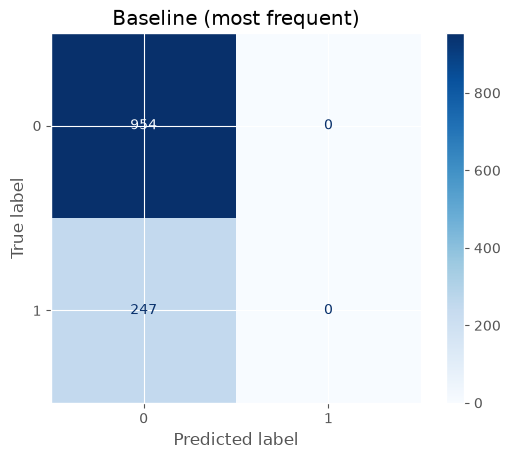

In [13]:
def evaluate(model, X_te, y_te, name="model"):
    y_pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1] if hasattr(model, "predict_proba") else None

    p, r, f1, _ = precision_recall_fscore_support(
        y_te, y_pred, average="binary", zero_division=0
    )
    print(f"=== {name} ===")
    print(classification_report(y_te, y_pred, digits=3, zero_division=0))
    if proba is not None:
        print("ROC-AUC:", round(roc_auc_score(y_te, proba), 3))

    ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred)).plot(cmap="Blues")
    plt.title(name)
    plt.show()

    return {"model": name, "precision": p, "recall": r, "f1": f1}


baseline = Pipeline([
    ("prep", preprocess),
    ("clf", DummyClassifier(strategy="most_frequent")),
])
baseline.fit(X_train, y_train)
baseline_metrics = evaluate(baseline, X_test, y_test, name="Baseline (most frequent)")

=== Logistic Regression (balanced) ===
              precision    recall  f1-score   support

           0      0.916     0.745     0.822       954
           1      0.428     0.737     0.542       247

    accuracy                          0.744      1201
   macro avg      0.672     0.741     0.682      1201
weighted avg      0.816     0.744     0.764      1201

ROC-AUC: 0.823


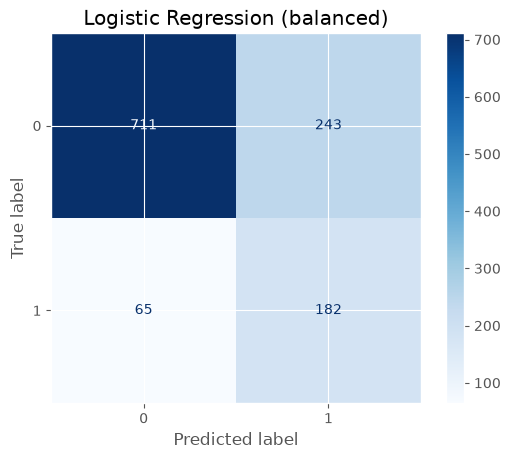

In [14]:
log_reg = Pipeline([
    ("prep", preprocess),
    ("clf", LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    )),
])
log_reg.fit(X_train, y_train)
log_metrics = evaluate(log_reg, X_test, y_test, name="Logistic Regression (balanced)")

=== Random Forest (balanced) ===
              precision    recall  f1-score   support

           0      0.863     0.901     0.882       954
           1      0.539     0.445     0.488       247

    accuracy                          0.808      1201
   macro avg      0.701     0.673     0.685      1201
weighted avg      0.796     0.808     0.801      1201

ROC-AUC: 0.804


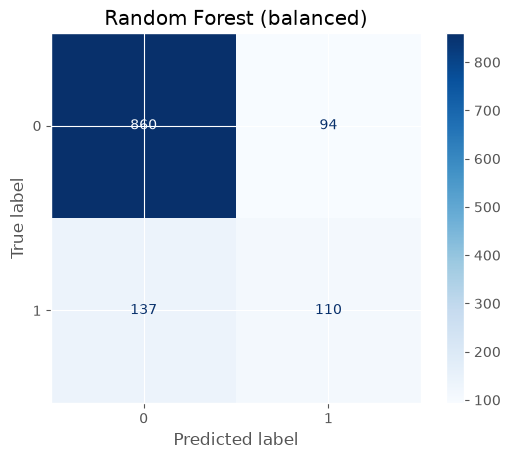

In [15]:
rf = Pipeline([
    ("prep", preprocess),
    ("clf", RandomForestClassifier(
        n_estimators=300,
        min_samples_leaf=2,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )),
])
rf.fit(X_train, y_train)
rf_metrics = evaluate(rf, X_test, y_test, name="Random Forest (balanced)")

In [16]:
results = pd.DataFrame([baseline_metrics, log_metrics, rf_metrics])
print(results.to_string(index=False))

# Keep the model with better late-class F1 and recall
final_model = log_reg
FINAL_NAME = "Logistic Regression (balanced)"
print("Selected final model:", FINAL_NAME)

                         model  precision   recall       f1
      Baseline (most frequent)   0.000000 0.000000 0.000000
Logistic Regression (balanced)   0.428235 0.736842 0.541667
      Random Forest (balanced)   0.539216 0.445344 0.487805
Selected final model: Logistic Regression (balanced)


Baseline: ~79% accuracy, 0 precision/recall/F1 on late. Logistic regression (balanced): ~0.44 precision, ~0.74 recall, ~0.55 F1 on late, ROC-AUC ~0.82. Random forest: nicer overall accuracy and late precision (~0.55), but late recall ~0.48 and F1 ~0.51.

I kept logistic regression for alerts. Missing a late load hurts more than an extra false alarm for this use case.

## 11. Model evaluation and alert threshold

Default probability cut is 0.5. I swept cuts on holdout probabilities and chose one with late recall at least 0.75, then the best F1 in that band.

In [17]:
y_proba = final_model.predict_proba(X_test)[:, 1]

rows = []
for thr in np.round(np.arange(0.20, 0.81, 0.05), 2):
    pred = (y_proba >= thr).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(
        y_test, pred, average="binary", zero_division=0
    )
    rows.append({
        "threshold": thr,
        "precision": round(p, 4),
        "recall": round(r, 4),
        "f1": round(f1, 4),
        "alerts": int(pred.sum()),
    })

threshold_table = pd.DataFrame(rows)
threshold_table

,threshold,precision,recall,f1,alerts
0,0.20,0.2786,0.9352,0.4294,829
1,0.25,0.2999,0.9190,0.4522,757
2,0.30,0.3270,0.8988,0.4795,679
3,0.35,0.3500,0.8785,0.5006,620
4,0.40,0.3775,0.8421,0.5213,551
5,0.45,0.4045,0.7976,0.5368,487
6,0.50,0.4282,0.7368,0.5417,425
7,0.55,0.4659,0.6923,0.5570,367
8,0.60,0.5033,0.6235,0.5570,306
9,0.65,0.5573,0.5709,0.5640,253


              precision    recall  f1-score   support

           0      0.930     0.696     0.796       954
           1      0.405     0.798     0.537       247

    accuracy                          0.717      1201
   macro avg      0.667     0.747     0.666      1201
weighted avg      0.822     0.717     0.743      1201



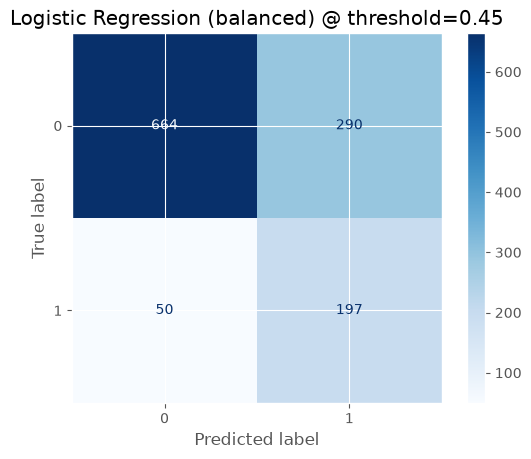

Chosen threshold: 0.45


In [18]:
ALERT_THRESHOLD = 0.45

y_alert = (y_proba >= ALERT_THRESHOLD).astype(int)
print(classification_report(y_test, y_alert, digits=3, zero_division=0))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_alert)).plot(cmap="Blues")
plt.title(f"{FINAL_NAME} @ threshold={ALERT_THRESHOLD}")
plt.show()

print("Chosen threshold:", ALERT_THRESHOLD)

Alert cut: 0.45.

At 0.45 on the test fold: late precision ~0.40, recall ~0.80, F1 ~0.54 (~484 alerts in 1,201 rows). Noisier than 0.50, but missed late shipments drop from 65 to about 51. I would rather review a longer Slack list than miss another customer call.

## 12. Model explainability

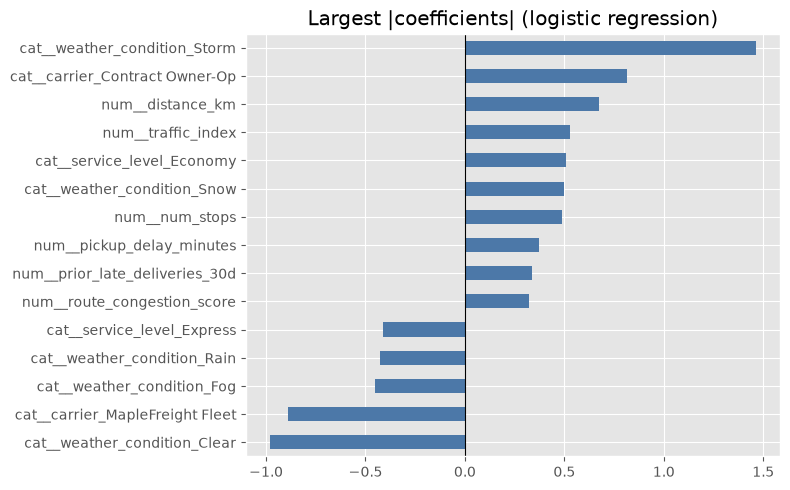

cat__weather_condition_Storm       1.462
cat__weather_condition_Clear      -0.979
cat__carrier_MapleFreight Fleet   -0.892
cat__carrier_Contract Owner-Op     0.816
num__distance_km                   0.676
num__traffic_index                 0.529
cat__service_level_Economy         0.507
cat__weather_condition_Snow        0.497
num__num_stops                     0.489
cat__weather_condition_Fog        -0.453
cat__weather_condition_Rain       -0.428
cat__service_level_Express        -0.410
num__pickup_delay_minutes          0.375
num__prior_late_deliveries_30d     0.336
num__route_congestion_score        0.321


In [19]:
clf = final_model.named_steps["clf"]
prep = final_model.named_steps["prep"]
feat_names = prep.get_feature_names_out()
coefs = pd.Series(clf.coef_[0], index=feat_names)
top = coefs.reindex(coefs.abs().sort_values(ascending=False).head(15).index)

fig, ax = plt.subplots(figsize=(8, 5))
top.sort_values().plot(kind="barh", ax=ax, color="#4C78A8")
ax.set_title("Largest |coefficients| (logistic regression)")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()
print(top.round(3).to_string())

Coefficients: storm and Contract Owner-Op increase late probability; clear weather and MapleFreight Fleet decrease it. Distance, traffic, Economy, extra stops and pickup delay also push risk up. Same story as the EDA plots.

## 13. Slack alert integration

I score the holdout set as a stand-in for freight still moving. The Slack text shows how many loads cleared the cut, then ID, destination, carrier and score for the top five. Webhook URL only in `.env`.

In [20]:
def build_dispatch_message(shipments: pd.DataFrame, threshold: float, top_n: int = 5) -> str:
    n = len(shipments)
    lines = [
        f":warning: *MapleFreight delay risk* - {n} shipment(s) above threshold {threshold:.2f}",
        "",
    ]
    top = shipments.nlargest(min(top_n, n), "risk_score")
    for _, row in top.iterrows():
        lines.append(
            f"- `{row['shipment_id']}` -> {row['destination_city']} | "
            f"{row['carrier']} | risk {row['risk_score']:.2f}"
        )
    if n > top_n:
        lines.append(f"_...and {n - top_n} more_")
    return "\n".join(lines)


def send_slack_alert(message: str) -> bool:
    webhook = os.getenv("SLACK_WEBHOOK_URL")
    if not webhook:
        print("SLACK_WEBHOOK_URL missing. Copy .env.example to .env and add your webhook.")
        return False
    try:
        resp = requests.post(webhook, json={"text": message}, timeout=15)
    except requests.RequestException as exc:
        print("Slack request failed:", type(exc).__name__)
        return False
    # never print the webhook URL
    print("Slack status:", resp.status_code)
    return resp.status_code == 200

In [21]:
scored = X_test.copy()
scored["risk_score"] = y_proba
scored["shipment_id"] = df.loc[X_test.index, "shipment_id"].values
scored["destination_city"] = df.loc[X_test.index, "destination_city"].values
scored["carrier"] = df.loc[X_test.index, "carrier"].values

high_risk = scored[scored["risk_score"] >= ALERT_THRESHOLD].copy()
print(f"High-risk shipments: {len(high_risk)}")

message = build_dispatch_message(high_risk, ALERT_THRESHOLD, top_n=5)
print("\n--- message preview ---\n")
print(message)

sent = send_slack_alert(message)
print("Posted to Slack:", sent)
print("Screenshot expected at:", SCREENSHOT_DIR / "slack_alert.png")

High-risk shipments: 487

--- message preview ---

:warning: *MapleFreight delay risk* - 487 shipment(s) above threshold 0.45

- `SHP-103230` -> Regina SK | Contract Owner-Op | risk 0.98
- `SHP-102910` -> Edmonton AB | QuebecExpress | risk 0.98
- `SHP-100273` -> Hamilton ON | NorthStar Carriers | risk 0.98
- `SHP-101710` -> Sudbury ON | MapleFreight Fleet | risk 0.98
- `SHP-105815` -> Quebec City QC | NorthStar Carriers | risk 0.97
_...and 482 more_
Slack status: 200
Posted to Slack: True
Screenshot expected at: d:\AML-3303-OTT01 Software Tools and Emerging\Assignment1\screenshots\slack_alert.png


## 14. Recommendations

1. Storm/snow days: hold or reschedule Economy when the promised window is tight.
2. Cap Contract Owner-Op on premium long hauls until their 30-day late count improves.
3. If pickup is already 20+ minutes late, re-check ETA before departure.
4. Shift more long, congested lanes to MapleFreight Fleet when capacity allows.
5. Start Slack at 0.45; raise the cut later if the channel is too busy.

## 15. Conclusion

The baseline looks fine on accuracy and useless on late detection. I would pilot balanced logistic regression at cut 0.45: ~0.54 F1 on the late class and roughly 80% of late loads flagged on the test set.

Weather, carrier type, route length/congestion and late pickup keep showing up. Slack keeps the payload short: count at risk, then a few IDs with destination, carrier and score for someone reading on a phone.